# Sorensen index plus IoU calculations
Calculates the spatial and temporal overlap for different ARDTs. Fig. S1 and Fig. 3 in Main text

In [1]:
import xarray as xa
import numpy as np
from glob import glob
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.font_manager import FontProperties as fp
import datetime as dt
import scipy.stats as sts
import geopandas as gpd
import regionmask
import matplotlib.colors as colors
import cftime
import pymannkendall as mk
import string

ERROR 1: PROJ: proj_create_from_database: Open of /glade/u/home/tcorrie/.conda/envs/rmask/share/proj failed


In [2]:
wusd3 = pd.read_csv('../wusd3_gcms.csv', index_col=0)
wusd3 = wusd3.drop(wusd3.index[[6]]).reset_index(drop=True)

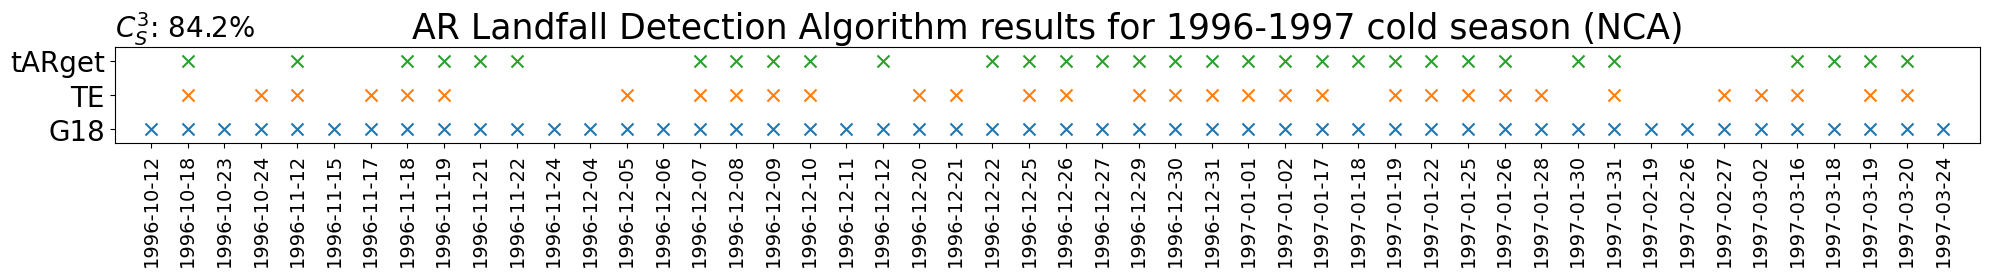

In [3]:
# Proof of concept test for one cold season. We picked the 1996-97 cold season using WRF-ERA5 data.

days_all_G18 = xa.open_dataset('/glade/work/tcorrie/ARdata/ARlandfall/G18/ARlandfall.G18.era5.nan.nc', use_cftime=True)
days9697_G18_cold = days_all_G18.sel(time=xa.cftime_range(start=cftime.datetime(
    1996, 10, 1, calendar='standard'), end=cftime.datetime(
    1997, 3, 31, calendar='standard'))).where(
    days_all_G18.landfall_nca == 1, drop=True)

days_all_TE = xa.open_dataset('/glade/work/tcorrie/ARdata/ARlandfall/TE/ARlandfall.TE.era5.nan.nc', use_cftime=True)
days9697_TE_cold = days_all_TE.sel(time=xa.cftime_range(start=cftime.datetime(
    1996, 10, 1, calendar='standard'), end=cftime.datetime(
    1997, 3, 31, calendar='standard'))).where(
    days_all_TE.landfall_nca == 1, drop=True)

days_all_tARget = xa.open_dataset('/glade/work/tcorrie/ARdata/ARlandfall/tARget/ARlandfall.tARget.era5.nan.nc', use_cftime=True)
days9697_tARget_cold = days_all_tARget.sel(time=xa.cftime_range(start=cftime.datetime(
    1996, 10, 1, calendar='standard'), end=cftime.datetime(
    1997, 3, 31, calendar='standard'))).where(
    days_all_tARget.landfall_nca == 1, drop=True)

days_G18 = [x.strftime('%Y-%m-%d') for x in days9697_G18_cold.time.values]
days_TE = [x.strftime('%Y-%m-%d') for x in days9697_TE_cold.time.values]
days_tARget = [x.strftime('%Y-%m-%d') for x in days9697_tARget_cold.time.values]

days_inter_G18TE = set(days_G18) & set(days_TE)
days_inter_G18tARget = set(days_G18) & set(days_tARget)
days_inter_TEtARget = set(days_TE) & set(days_tARget)
days_inter_all = set(days_G18) & set(days_TE) & set(days_tARget)

days_all = sorted(list(set(days_G18) | set(days_TE) | set(days_tARget)))

plot_G18 = np.array([1 if day in days_G18 else 0 for day in days_all])
plot_TE = np.array([1 if day in days_TE else 0 for day in days_all])
plot_tARget = np.array([1 if day in days_tARget else 0 for day in days_all])

sorensen_index_numerator = len(days_inter_G18TE) + len(days_inter_G18tARget) + len(days_inter_TEtARget) - len(days_inter_all)
sorensen_index_denominator = len(days_G18) + len(days_TE) + len(days_tARget)

sorensen_score = 100 * (1.5 * sorensen_index_numerator / sorensen_index_denominator)

sslogo = r'$C_S^3$'

f7, a7 = plt.subplots(1, 1, figsize=(20, 3))
a7.scatter(days_all, np.multiply(plot_G18, 0.25), marker='x', s=75)
a7.scatter(days_all, np.multiply(plot_TE, 0.50), marker='x', s=75)
a7.scatter(days_all, np.multiply(plot_tARget, 0.75), marker='x', s=75)
a7.set_yticks([0.25, 0.50, 0.75])
a7.set_yticklabels(["G18", "TE", "tARget"], fontsize=20)
a7.set_xticks(days_all)
a7.set_xticklabels(days_all, rotation=90, ha='center', fontsize=14)
a7.set_ylim(0.15, 0.85)
a7.set_xlim(-1, len(days_all))
a7.text(0, 1.1, f"{sslogo}: {sorensen_score:.1f}%", transform=a7.transAxes, fontsize=20)
a7.set_title("AR Landfall Detection Algorithm results for 1996-1997 cold season (NCA)", fontsize=25)
f7.tight_layout()
f7.savefig('/glade/work/tcorrie/ARdata/Figures/JoC/cs3_9697_NCA_supp.png') # Figure S1

In [4]:
# WRF-ERA5 Sorensen Index

days_all_G18 = xa.open_dataset('/glade/work/tcorrie/ARdata/ARlandfall/G18/ARlandfall.G18.era5.nan.nc', use_cftime=True)
days_all_TE = xa.open_dataset('/glade/work/tcorrie/ARdata/ARlandfall/TE/ARlandfall.TE.era5.nan.nc', use_cftime=True)
days_all_tARget = xa.open_dataset('/glade/work/tcorrie/ARdata/ARlandfall/tARget/ARlandfall.tARget.era5.nan.nc', use_cftime=True)
for region in ['SCA', 'NCA', 'OR', 'WA']:
    print(region)
    years_era5 = np.zeros(2025-1950)
    
    for yr in range(1950, 2025):
        print(yr, end='\r')
    
        # Get necessary cold season
        days_all_G18_cold_yr = days_all_G18.sel(time=xa.cftime_range(start=cftime.datetime(
            yr, 10, 1, calendar='standard'), end=cftime.datetime(
            yr+1, 3, 31, calendar='standard'), inclusive='left')).where(days_all_G18[f'landfall_{region.lower()}'] == 1, drop=True)
        days_all_TE_cold_yr = days_all_TE.sel(time=xa.cftime_range(start=cftime.datetime(
            yr, 10, 1, calendar='standard'), end=cftime.datetime(
            yr+1, 3, 31, calendar='standard'), inclusive='left')).where(days_all_TE[f'landfall_{region.lower()}'] == 1, drop=True)
        days_all_tARget_cold_yr = days_all_tARget.sel(time=xa.cftime_range(start=cftime.datetime(
            yr, 10, 1, calendar='standard'), end=cftime.datetime(
            yr+1, 3, 31, calendar='standard'), inclusive='left')).where(days_all_tARget[f'landfall_{region.lower()}'] == 1, drop=True)
    
        # Get AR days for a specific cold season
        days_G18_yr = [x.strftime('%Y-%m-%d') for x in days_all_G18_cold_yr.time.values]
        days_TE_yr = [x.strftime('%Y-%m-%d') for x in days_all_TE_cold_yr.time.values]
        days_tARget_yr = [x.strftime('%Y-%m-%d') for x in days_all_tARget_cold_yr.time.values]
    
        # Get intersections of pair-wise AR days and all 3 ARDTs
        days_G18TE_yr = set(days_G18_yr) & set(days_TE_yr)
        days_G18tARget_yr = set(days_G18_yr) & set(days_tARget_yr)
        days_TEtARget_yr = set(days_TE_yr) & set(days_tARget_yr)
        days_all_yr = set(days_G18_yr) & set(days_TE_yr) & set(days_tARget_yr)
    
        sorensen_index_numerator = len(days_G18TE_yr) + len(days_G18tARget_yr) + len(days_TEtARget_yr) - len(days_all_yr)
        sorensen_index_denominator = len(days_G18_yr) + len(days_TE_yr) + len(days_tARget_yr)
    
        sorensen_index_yr = 100 * (1.5 * sorensen_index_numerator / sorensen_index_denominator)
        
        # Add Sorensen index to the array to be plotted
        years_era5[yr-1950] = sorensen_index_yr
    print("")
    np.save(f'intermediate_numpy_files/sindx_era5_{region}.npy', years_era5)

SCA
NCA4
OR24
WA24


In [5]:
# CMIP6 Sorensen Index

wusd3 = pd.read_csv('../wusd3_gcms.csv', index_col=0)
wusd3 = wusd3.drop(wusd3.index[[6]]).reset_index(drop=True)

years_cmip6 = np.zeros((len(wusd3.index), 2100-1980))
for region in ['SCA', 'NCA', 'OR', 'WA']:
    print(region)
    for i in range(len(wusd3.index)):
        model = wusd3.loc[i, 'Model']
        member = wusd3.loc[i, 'Member']
        calendar = wusd3.loc[i, 'Calendar']
        print(f"{model}/{member}")
        
        days_all_G18 = xa.open_dataset(f'/glade/work/tcorrie/ARdata/ARlandfall/G18/ARlandfall.G18.{model}.{member}.nc', use_cftime=True)
        days_all_TE = xa.open_dataset(f'/glade/work/tcorrie/ARdata/ARlandfall/TE/ARlandfall.TE.{model}.{member}.nc', use_cftime=True)
        days_all_tARget = xa.open_dataset(f'/glade/work/tcorrie/ARdata/ARlandfall/tARget/ARlandfall.tARget.{model}.{member}.nc', use_cftime=True)
    
        for yr in range(1980, 2100):
            print(yr, end='\r')
            lastday = 30 if i==14 else 31
        
            # Get necessary cold season
            days_all_G18_cold_yr = days_all_G18.sel(time=xa.cftime_range(start=cftime.datetime(
                yr, 10, 1, calendar=calendar), end=cftime.datetime(
                yr+1, 3, lastday, calendar=calendar), inclusive='left')).where(days_all_G18[f'landfall_{region.lower()}'] == 1, drop=True)
            days_all_TE_cold_yr = days_all_TE.sel(time=xa.cftime_range(start=cftime.datetime(
                yr, 10, 1, calendar=calendar), end=cftime.datetime(
                yr+1, 3, lastday, calendar=calendar), inclusive='left')).where(days_all_TE[f'landfall_{region.lower()}'] == 1, drop=True)
            days_all_tARget_cold_yr = days_all_tARget.sel(time=xa.cftime_range(start=cftime.datetime(
                yr, 10, 1, calendar=calendar), end=cftime.datetime(
                yr+1, 3, lastday, calendar=calendar), inclusive='left')).where(days_all_tARget[f'landfall_{region.lower()}'] == 1, drop=True)
        
            # Get AR days for a specific cold season
            days_G18_yr = [x.strftime('%Y-%m-%d') for x in days_all_G18_cold_yr.time.values]
            days_TE_yr = [x.strftime('%Y-%m-%d') for x in days_all_TE_cold_yr.time.values]
            days_tARget_yr = [x.strftime('%Y-%m-%d') for x in days_all_tARget_cold_yr.time.values]
        
            # Get intersections of pair-wise AR days and all 3 ARDTs
            days_G18TE_yr = set(days_G18_yr) & set(days_TE_yr)
            days_G18tARget_yr = set(days_G18_yr) & set(days_tARget_yr)
            days_TEtARget_yr = set(days_TE_yr) & set(days_tARget_yr)
            days_all_yr = set(days_G18_yr) & set(days_TE_yr) & set(days_tARget_yr)
        
            sorensen_index_numerator = len(days_G18TE_yr) + len(days_G18tARget_yr) + len(days_TEtARget_yr) - len(days_all_yr)
            sorensen_index_denominator = len(days_G18_yr) + len(days_TE_yr) + len(days_tARget_yr)
        
            sorensen_index_yr = 100 * (1.5 * sorensen_index_numerator / sorensen_index_denominator)
            
            # Add Sorensen index to the array to be plotted
            years_cmip6[i][yr-1980] = sorensen_index_yr
        print("")
        np.save(f'intermediate_numpy_files/sindx_cmip6_{region}.npy', years_cmip6)

SCA
access-cm2/r5i1p1f1
canesm5/r1i1p2f1
cesm2/r11i1p1f1
cnrm-esm2-1/r1i1p1f2
ec-earth3/r1i1p1f1
ec-earth3-veg/r1i1p1f1
fgoals-g3/r1i1p1f1
giss-e2-1-g/r1i1p1f2
miroc6/r1i1p1f1
mpi-esm1-2-hr/r3i1p1f1
mpi-esm1-2-hr/r7i1p1f1
mpi-esm1-2-lr/r7i1p1f1
noresm2-mm/r1i1p1f1
taiesm1/r1i1p1f1
ukesm1-0-ll/r2i1p1f2
NCA9
access-cm2/r5i1p1f1
canesm5/r1i1p2f1
cesm2/r11i1p1f1
cnrm-esm2-1/r1i1p1f2
ec-earth3/r1i1p1f1
ec-earth3-veg/r1i1p1f1
fgoals-g3/r1i1p1f1
giss-e2-1-g/r1i1p1f2
miroc6/r1i1p1f1
mpi-esm1-2-hr/r3i1p1f1
mpi-esm1-2-hr/r7i1p1f1
mpi-esm1-2-lr/r7i1p1f1
noresm2-mm/r1i1p1f1
taiesm1/r1i1p1f1
ukesm1-0-ll/r2i1p1f2
OR99
access-cm2/r5i1p1f1
canesm5/r1i1p2f1
cesm2/r11i1p1f1
cnrm-esm2-1/r1i1p1f2
ec-earth3/r1i1p1f1
ec-earth3-veg/r1i1p1f1
fgoals-g3/r1i1p1f1
giss-e2-1-g/r1i1p1f2
miroc6/r1i1p1f1
mpi-esm1-2-hr/r3i1p1f1
mpi-esm1-2-hr/r7i1p1f1
mpi-esm1-2-lr/r7i1p1f1
noresm2-mm/r1i1p1f1
taiesm1/r1i1p1f1
ukesm1-0-ll/r2i1p1f2
WA99
access-cm2/r5i1p1f1
canesm5/r1i1p2f1
cesm2/r11i1p1f1
cnrm-esm2-1/r1i1p1f2
ec-earth3/

In [6]:
# CESM2-LE Sorensen Index
for region in ['SCA', 'NCA', 'OR', 'WA']:
    print(region)
    years_cesm2le = np.zeros((10, 2100-1850))
    
    for i, m in enumerate(range(1011, 1201, 20)):
        model = 'cesm2-le'
        member = str(m)
        calendar = '365_day'
        print(f"{model}/{member}")
        
        days_all_G18 = xa.open_dataset(f'/glade/work/tcorrie/ARdata/ARlandfall/G18/ARlandfall.G18.{model}.{member}.nc', use_cftime=True)
        days_all_TE = xa.open_dataset(f'/glade/work/tcorrie/ARdata/ARlandfall/TE/ARlandfall.TE.{model}.{member}.nc', use_cftime=True)
        days_all_tARget = xa.open_dataset(f'/glade/work/tcorrie/ARdata/ARlandfall/tARget/ARlandfall.tARget.{model}.{member}.nc', use_cftime=True)
    
        for yr in range(1850, 2100):
            print(yr, end='\r')
            lastday = 31
        
            # Get necessary cold season
            days_all_G18_cold_yr = days_all_G18.sel(time=xa.cftime_range(start=cftime.datetime(
                yr, 10, 1, calendar=calendar), end=cftime.datetime(
                yr+1, 3, lastday, calendar=calendar), inclusive='left')).where(days_all_G18[f'landfall_{region.lower()}'] == 1, drop=True)
            days_all_TE_cold_yr = days_all_TE.sel(time=xa.cftime_range(start=cftime.datetime(
                yr, 10, 1, calendar=calendar), end=cftime.datetime(
                yr+1, 3, lastday, calendar=calendar), inclusive='left')).where(days_all_TE[f'landfall_{region.lower()}'] == 1, drop=True)
            days_all_tARget_cold_yr = days_all_tARget.sel(time=xa.cftime_range(start=cftime.datetime(
                yr, 10, 1, calendar=calendar), end=cftime.datetime(
                yr+1, 3, lastday, calendar=calendar), inclusive='left')).where(days_all_tARget[f'landfall_{region.lower()}'] == 1, drop=True)
        
            # Get AR days for a specific cold season
            days_G18_yr = [x.strftime('%Y-%m-%d') for x in days_all_G18_cold_yr.time.values]
            days_TE_yr = [x.strftime('%Y-%m-%d') for x in days_all_TE_cold_yr.time.values]
            days_tARget_yr = [x.strftime('%Y-%m-%d') for x in days_all_tARget_cold_yr.time.values]
        
            # Get intersections of pair-wise AR days and all 3 ARDTs
            days_G18TE_yr = set(days_G18_yr) & set(days_TE_yr)
            days_G18tARget_yr = set(days_G18_yr) & set(days_tARget_yr)
            days_TEtARget_yr = set(days_TE_yr) & set(days_tARget_yr)
            days_all_yr = set(days_G18_yr) & set(days_TE_yr) & set(days_tARget_yr)
        
            sorensen_index_numerator = len(days_G18TE_yr) + len(days_G18tARget_yr) + len(days_TEtARget_yr) - len(days_all_yr)
            sorensen_index_denominator = len(days_G18_yr) + len(days_TE_yr) + len(days_tARget_yr)
        
            sorensen_index_yr = 100 * (1.5 * sorensen_index_numerator / sorensen_index_denominator)
            
            # Add Sorensen index to the array to be plotted
            years_cesm2le[i][yr-1850] = sorensen_index_yr
        np.save(f'intermediate_numpy_files/sindx_cesm2le_{region}.npy', years_cesm2le)

SCA
cesm2-le/1011
cesm2-le/1031
cesm2-le/1051
cesm2-le/1071
cesm2-le/1091
cesm2-le/1111
cesm2-le/1131
cesm2-le/1151
cesm2-le/1171
cesm2-le/1191
NCA9
cesm2-le/1011
cesm2-le/1031
cesm2-le/1051
cesm2-le/1071
cesm2-le/1091
cesm2-le/1111
cesm2-le/1131
cesm2-le/1151
cesm2-le/1171
cesm2-le/1191
OR99
cesm2-le/1011
cesm2-le/1031
cesm2-le/1051
cesm2-le/1071
cesm2-le/1091
cesm2-le/1111
cesm2-le/1131
cesm2-le/1151
cesm2-le/1171
cesm2-le/1191
WA99
cesm2-le/1011
cesm2-le/1031
cesm2-le/1051
cesm2-le/1071
cesm2-le/1091
cesm2-le/1111
cesm2-le/1131
cesm2-le/1151
cesm2-le/1171
cesm2-le/1191


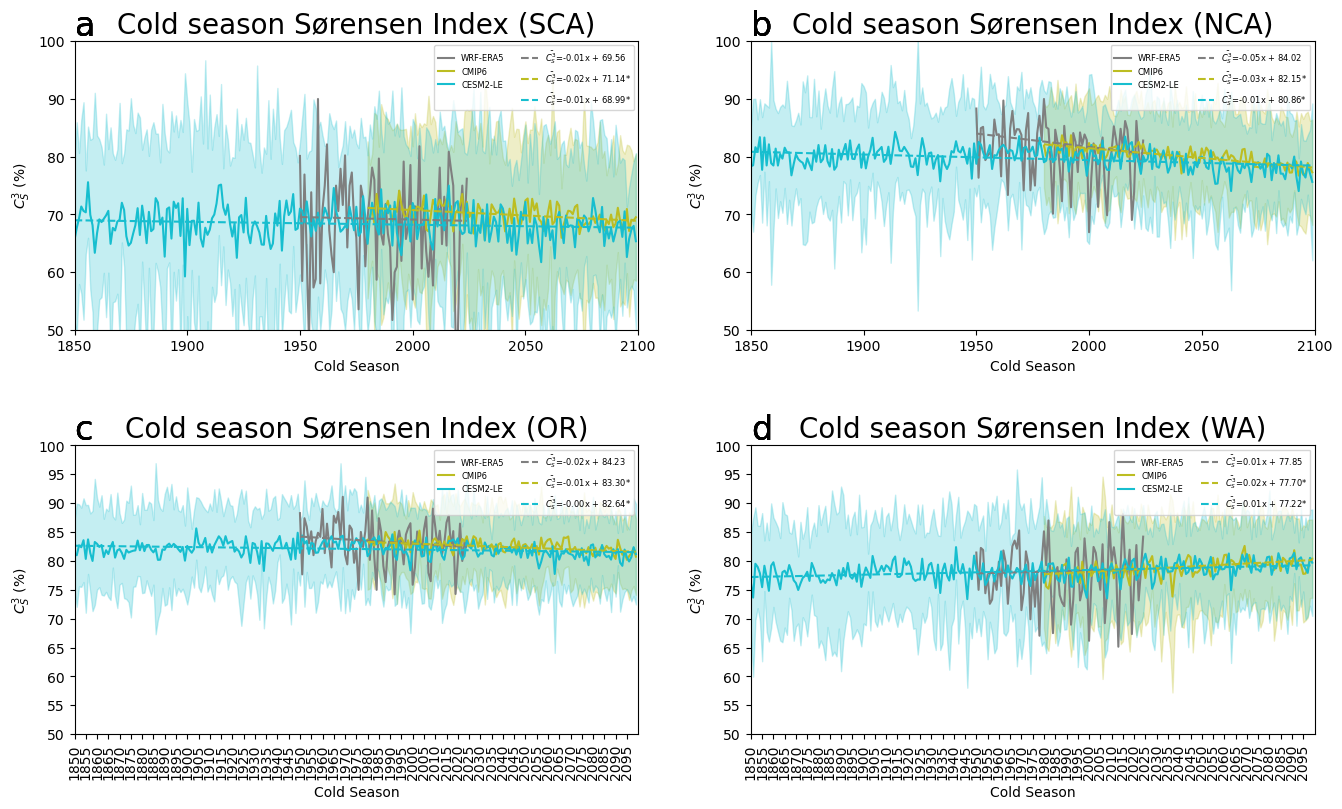

In [3]:
# Plot of the Sorensen Index in each lat. zone. This figure is not in the main or supplmental.

sorsym = r'$C_S^3$'
sorsym_bar = r'$\bar{C_S^3}$'
f9, a9 = plt.subplots(2, 2, figsize=(16, 9))
f9.subplots_adjust(hspace=0.4)

for ct, region in enumerate(['SCA', 'NCA', 'OR', 'WA']):
    sindx_era5 = np.load(f'intermediate_numpy_files/sindx_era5_{region}.npy')
    sindx_cmip6 = np.load(f'intermediate_numpy_files/sindx_cmip6_{region}.npy')
    sindx_cesm2le = np.load(f'intermediate_numpy_files/sindx_cesm2le_{region}.npy')

    sindx_era5_mean = sindx_era5
    sindx_cmip6_mean = np.mean(sindx_cmip6, axis=0)
    sindx_cmip6_std = np.std(sindx_cmip6, axis=0)
    sindx_cesm2le_mean = np.mean(sindx_cesm2le, axis=0)
    sindx_cesm2le_std = np.std(sindx_cesm2le, axis=0)


    a9[ct//2, ct%2].plot(np.arange(1950, 2025), sindx_era5_mean, label='WRF-ERA5', color='C7')
    a9[ct//2, ct%2].plot(np.arange(1980, 2100), sindx_cmip6_mean, label='CMIP6', color='C8')
    a9[ct//2, ct%2].plot(np.arange(1850, 2100), sindx_cesm2le_mean, label='CESM2-LE', color='C9')
    a9[ct//2, ct%2].fill_between(np.arange(1980, 2100), sindx_cmip6_mean - 1.96 * sindx_cmip6_std, sindx_cmip6_mean + 1.96 * sindx_cmip6_std, color='C8', alpha=0.25)
    a9[ct//2, ct%2].fill_between(np.arange(1850, 2100), sindx_cesm2le_mean - 1.96 * sindx_cesm2le_std, sindx_cesm2le_mean + 1.96 * sindx_cesm2le_std, color='C9', alpha=0.25)
    a9[ct//2, ct%2].set_xlabel("Cold Season")
    a9[ct//2, ct%2].set_ylabel(f"{sorsym} (%)")
    a9[ct//2, ct%2].set_ylim(50, 100)
    a9[ct//2, ct%2].set_xlim(1850, 2100)
    if ct>=2:
        a9[ct//2, ct%2].set_xticks(np.arange(1850, 2100, 5))
        a9[ct//2, ct%2].set_xticklabels(np.arange(1850, 2100, 5), rotation=90)
        a9[ct//2, ct%2].set_yticks(np.arange(50, 101, 5))
        a9[ct//2, ct%2].set_yticklabels(np.arange(50, 101, 5))
    #a9.axhline(np.mean(years), 0, 1, linestyle='dashed', c='k')
    #a9.text(0.98, 0.95, f"Mean {sorsym}: {np.mean(years):.1f}%", transform=a8.transAxes, ha='right')
    a9[ct//2, ct%2].set_title(f"Cold season Sørensen Index ({region})", fontsize=20)
    
    mktrend_era5 = mk.original_test(sindx_era5_mean)
    mktrend_cmip6 = mk.original_test(sindx_cmip6_mean)
    mktrend_cesm2le = mk.original_test(sindx_cesm2le_mean)
    
    era5_label = f"{sorsym_bar}={mktrend_era5.slope:.2f}x + {mktrend_era5.intercept:.2f}*" if mktrend_era5.p < 0.05 else f"{sorsym_bar}={mktrend_era5.slope:.2f}x + {mktrend_era5.intercept:.2f}"
    cmip6_label = f"{sorsym_bar}={mktrend_cmip6.slope:.2f}x + {mktrend_cmip6.intercept:.2f}*" if mktrend_cmip6.p < 0.05 else f"{sorsym_bar}={mktrend_cmip6.slope:.2f}x + {mktrend_cmip6.intercept:.2f}"
    cesm2le_label = f"{sorsym_bar}={mktrend_cesm2le.slope:.2f}x + {mktrend_cesm2le.intercept:.2f}*" if mktrend_cesm2le.p < 0.05 else f"{sorsym_bar}={mktrend_cesm2le.slope:.2f}x + {mktrend_cesm2le.intercept:.2f}"
    
    a9[ct//2, ct%2].plot(np.arange(1950,2025), mktrend_era5.slope * np.arange(75) + mktrend_era5.intercept, color='C7', linestyle='dashed', label=era5_label)
    a9[ct//2, ct%2].plot(np.arange(1980,2100), mktrend_cmip6.slope * np.arange(120) + mktrend_cmip6.intercept, color='C8', linestyle='dashed', label=cmip6_label)
    a9[ct//2, ct%2].plot(np.arange(1850,2100), mktrend_cesm2le.slope * np.arange(250) + mktrend_cesm2le.intercept, color='C9', linestyle='dashed', label=cesm2le_label)
    a9[ct//2, ct%2].legend(loc='upper right', ncols=2, fontsize=6)

    for i in range(4):
        a9[i//2, i%2].text(0, 1.02, string.ascii_lowercase[i], fontsize=24, transform=a9[i//2, i%2].transAxes)


In [4]:
# the definition of the IoU used in this paper.
def calc_mean_iou_3way(model, member, region):

    coast_G18 = xa.open_dataset(f'/glade/work/tcorrie/ARdata/ARcoast/G18/ARcoast.G18.{model}.{member}.nc')
    coast_TE = xa.open_dataset(f'/glade/work/tcorrie/ARdata/ARcoast/TE/ARcoast.TE.{model}.{member}.nc')
    coast_tARget = xa.open_dataset(f'/glade/work/tcorrie/ARdata/ARcoast/tARget/ARcoast.tARget.{model}.{member}.nc')
    days_all_G18 = xa.open_dataset(f'/glade/work/tcorrie/ARdata/ARlandfall/G18/ARlandfall.G18.{model}.{member}.nc', use_cftime=True)
    days_all_TE = xa.open_dataset(f'/glade/work/tcorrie/ARdata/ARlandfall/TE/ARlandfall.TE.{model}.{member}.nc', use_cftime=True)
    days_all_tARget = xa.open_dataset(f'/glade/work/tcorrie/ARdata/ARlandfall/tARget/ARlandfall.tARget.{model}.{member}.nc', use_cftime=True)
    
    coast_all = xa.Dataset(
        coords={"time": coast_G18.time.values, "lat": coast_G18.lat.values, "ARDT": ['G18', 'TE', 'tARget']}, 
        data_vars={"ARcoast": (("time", "lat", "ARDT"), np.zeros((len(coast_G18.time),len(coast_G18.lat),3)))}
    )
    coast_all.loc[{'ARDT':'G18'}] = coast_G18.ARcoast
    coast_all.loc[{'ARDT':'TE'}] = coast_TE.ARcoast
    coast_all.loc[{'ARDT':'tARget'}] = coast_tARget.ARcoast.clip(0, None)
    
    days_all = xa.Dataset(
        coords={"time": days_all_G18.time.values, "ARDT": ['G18', 'TE', 'tARget']}, 
        data_vars={"landfall_wus": (("time", "ARDT"), np.zeros((len(days_all_G18.time),3))),
                   "landfall_sca": (("time", "ARDT"), np.zeros((len(days_all_G18.time),3))),
                   "landfall_nca": (("time", "ARDT"), np.zeros((len(days_all_G18.time),3))),
                   "landfall_or": (("time", "ARDT"), np.zeros((len(days_all_G18.time),3))),
                   "landfall_wa": (("time", "ARDT"), np.zeros((len(days_all_G18.time),3))),
                  }
    )
    days_all.loc[{'ARDT':'G18'}] = days_all_G18
    days_all.loc[{'ARDT':'TE'}] = days_all_TE
    days_all.loc[{'ARDT':'tARget'}] = days_all_tARget
    
    days_cold = days_all.where((days_all.time.dt.month >= 10) | ((days_all.time.dt.month <= 3)), drop=True).sum(dim='ARDT')
    days_cold_allagree = days_cold.where(days_cold[f'landfall_{region.lower()}'] == 3, drop=True).time
    coast_allagree = coast_all.sel(time=days_cold_allagree)

    regional_bounds = {'SCA': slice(32.49, 37.21), 'NCA': slice(37.19, 42.01), 'OR': slice(41.99, 46.31), 'WA': slice(46.29, 48.51)}
    
    coast_allagree_intersection = coast_allagree.all(dim='ARDT').sel(lat=regional_bounds[region]).astype('int').sum(dim='lat')
    coast_allagree_union = coast_allagree.any(dim='ARDT').sel(lat=regional_bounds[region]).astype('int').sum(dim='lat')
    
    coast_allagree_ratio = coast_allagree_intersection/coast_allagree_union
    coast_allagree_ratio['cold_season'] = xa.where(coast_allagree_ratio.time.dt.month >= 10, coast_allagree_ratio.time.dt.year, coast_allagree_ratio.time.dt.year-1)
    
    coast_iou_coldseason = coast_allagree_ratio.groupby('cold_season').mean()
    return coast_iou_coldseason

In [5]:
# WRF-ERA5 IoU

iou_era5 = xa.Dataset(
    coords = {'cold_season': np.arange(1950,2025), 'region': ['SCA', 'NCA', 'OR', 'WA']},
    data_vars = {'mean_iou': (['cold_season', 'region'], np.zeros((75, 4)))}
)

for region in iou_era5.region.values:
    iou_ds = calc_mean_iou_3way('era5', 'nan', region)
    iou_era5['mean_iou'].loc[{'region': region}] = iou_ds.ARcoast.data

In [7]:
# CMIP6 IoU

iou_cmip6 = xa.Dataset(
    coords = {'cold_season': np.arange(1980, 2100), 'config': [f'{mn}_{mm}' for mn, mm in zip(wusd3['Model Name'].values, wusd3['Member'].values)], 'region': ['SCA', 'NCA', 'OR', 'WA']},
    data_vars = {'mean_iou': (['cold_season', 'config', 'region'], np.zeros((120, len(wusd3['Model Name'].values), 4)))}
)

for row in wusd3.index:
    model = wusd3.loc[row, 'Model']
    model_name = wusd3.loc[row, 'Model Name']
    member = wusd3.loc[row, 'Member']
    for region in iou_cmip6.region.values:
        print(f"{model:20}/{member:10}/{region:4}", end='\r')
        iou_ds = calc_mean_iou_3way(model, member, region)
        iou_ds = iou_ds.reindex(cold_season=iou_cmip6.cold_season.values, fill_value=0)
        iou_cmip6['mean_iou'].loc[{'region': region, 'config': f'{model_name}_{member}'}] = iou_ds.ARcoast.data

In [9]:
# CESM2-LE IoU
iou_cesm2le = xa.Dataset(
    coords = {'cold_season': np.arange(1850, 2100), 'config': [f"CESM2-LE_{mm}" for mm in np.arange(1011,1201,20)], 'region': ['SCA', 'NCA', 'OR', 'WA']},
    data_vars = {'mean_iou': (['cold_season', 'config', 'region'], np.zeros((250, 10, 4)))}
)

for mem in np.arange(1011,1201,20):
    model = 'cesm2-le'
    model_name = 'CESM2-LE'
    member = mem
    for region in iou_cesm2le.region.values:
        print(f"{model:12}/{member:4}/{region:4}", end='\r')
        iou_ds = calc_mean_iou_3way(model, member, region)
        iou_ds = iou_ds.reindex(cold_season=iou_cesm2le.cold_season.values, fill_value=0)
        iou_cesm2le['mean_iou'].loc[{'region': region, 'config': f'{model_name}_{member}'}] = iou_ds.ARcoast.data

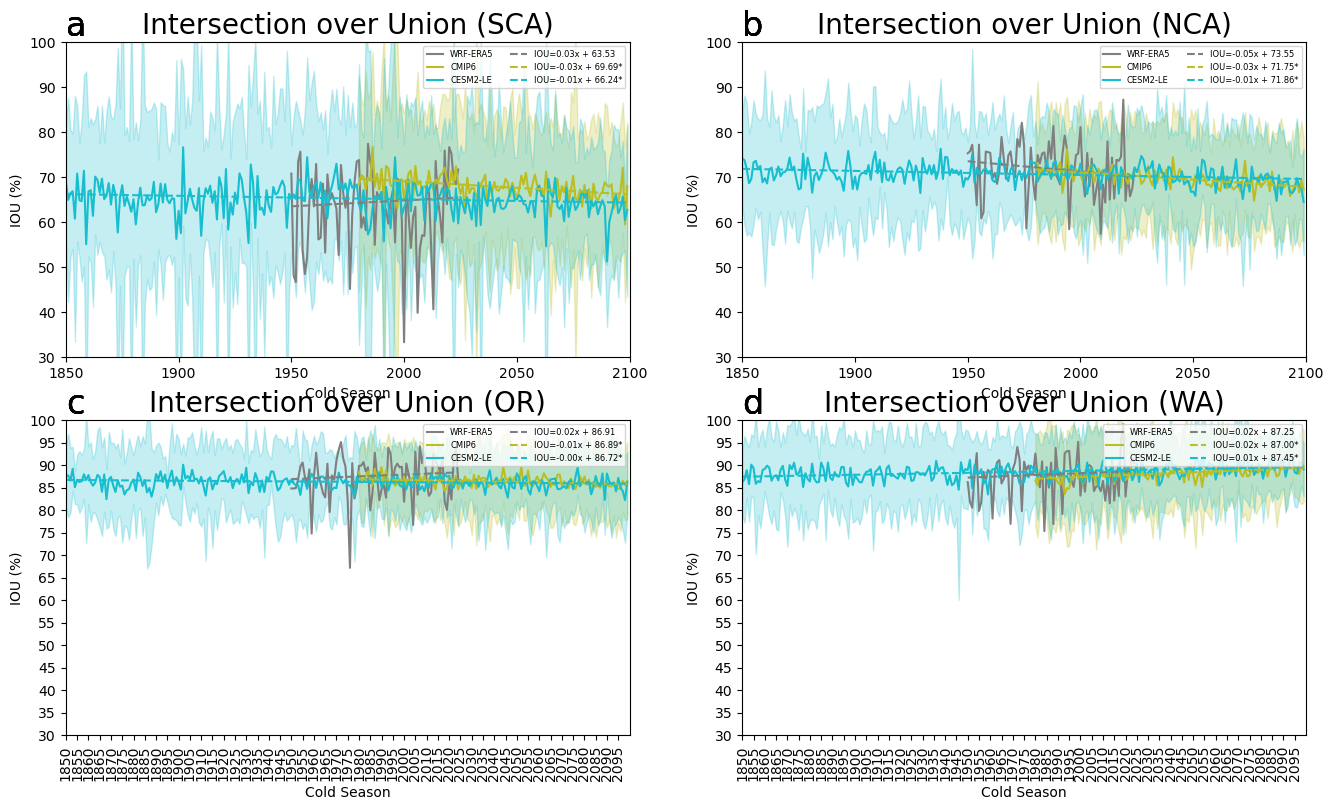

In [11]:
# Plot of the Sorensen Index in each lat. zone. This figure is not in the main or supplmental.

f10, a10 = plt.subplots(2, 2, figsize=(16, 9))

for ct, region in enumerate(['SCA', 'NCA', 'OR', 'WA']):
    iou_era5_region = iou_era5.sel(region=region)
    iou_cmip6_region = iou_cmip6.sel(region=region)
    iou_cesm2le_region = iou_cesm2le.sel(region=region)

    iou_era5_region_mean = iou_era5_region.mean_iou*100
    iou_cmip6_region_mean = iou_cmip6_region.mean_iou.mean(dim='config')*100
    iou_cmip6_region_std = iou_cmip6_region.mean_iou.std(dim='config')*100
    iou_cesm2le_region_mean = iou_cesm2le_region.mean_iou.mean(dim='config')*100
    iou_cesm2le_region_std = iou_cesm2le_region.mean_iou.std(dim='config')*100


    a10[ct//2, ct%2].plot(np.arange(1950, 2025), iou_era5_region_mean, label='WRF-ERA5', color='C7')
    a10[ct//2, ct%2].plot(np.arange(1980, 2100), iou_cmip6_region_mean, label='CMIP6', color='C8')
    a10[ct//2, ct%2].plot(np.arange(1850, 2100), iou_cesm2le_region_mean, label='CESM2-LE', color='C9')
    a10[ct//2, ct%2].fill_between(np.arange(1980, 2100), iou_cmip6_region_mean - 1.96 * iou_cmip6_region_std, iou_cmip6_region_mean + 1.96 * iou_cmip6_region_std, color='C8', alpha=0.25)
    a10[ct//2, ct%2].fill_between(np.arange(1850, 2100), iou_cesm2le_region_mean - 1.96 * iou_cesm2le_region_std, iou_cesm2le_region_mean + 1.96 * iou_cesm2le_region_std, color='C9', alpha=0.25)
    a10[ct//2, ct%2].set_xlabel("Cold Season")
    a10[ct//2, ct%2].set_ylabel("IOU (%)")
    a10[ct//2, ct%2].set_ylim(30, 100)
    a10[ct//2, ct%2].set_xlim(1850, 2100)
    if ct>=2:
        a10[ct//2, ct%2].set_xticks(np.arange(1850, 2100, 5))
        a10[ct//2, ct%2].set_xticklabels(np.arange(1850, 2100, 5), rotation=90)
        a10[ct//2, ct%2].set_yticks(np.arange(30, 101, 5))
        a10[ct//2, ct%2].set_yticklabels(np.arange(30, 101, 5))
    #a9.axhline(np.mean(years), 0, 1, linestyle='dashed', c='k')
    #a9.text(0.98, 0.95, f"Mean {sorsym}: {np.mean(years):.1f}%", transform=a8.transAxes, ha='right')
    a10[ct//2, ct%2].set_title(f"Intersection over Union ({region})", fontsize=20)

    mktrend_iou_era5 = mk.original_test(iou_era5_region_mean)
    mktrend_iou_cmip6 = mk.original_test(iou_cmip6_region_mean)
    mktrend_iou_cesm2le = mk.original_test(iou_cesm2le_region_mean)
    
    era5_iou_label = f"IOU={mktrend_iou_era5.slope:.2f}x + {mktrend_iou_era5.intercept:.2f}*" if mktrend_iou_era5.p < 0.05 else f"IOU={mktrend_iou_era5.slope:.2f}x + {mktrend_iou_era5.intercept:.2f}"
    cmip6_iou_label = f"IOU={mktrend_iou_cmip6.slope:.2f}x + {mktrend_iou_cmip6.intercept:.2f}*" if mktrend_iou_cmip6.p < 0.05 else f"IOU={mktrend_iou_cmip6.slope:.2f}x + {mktrend_iou_cmip6.intercept:.2f}"
    cesm2le_iou_label = f"IOU={mktrend_iou_cesm2le.slope:.2f}x + {mktrend_iou_cesm2le.intercept:.2f}*" if mktrend_iou_cesm2le.p < 0.05 else f"IOU={mktrend_iou_cesm2le.slope:.2f}x + {mktrend_iou_cesm2le.intercept:.2f}"
    
    a10[ct//2, ct%2].plot(np.arange(1950,2025), mktrend_iou_era5.slope * np.arange(75) + mktrend_iou_era5.intercept, color='C7', linestyle='dashed', label=era5_iou_label)
    a10[ct//2, ct%2].plot(np.arange(1980,2100), mktrend_iou_cmip6.slope * np.arange(120) + mktrend_iou_cmip6.intercept, color='C8', linestyle='dashed', label=cmip6_iou_label)
    a10[ct//2, ct%2].plot(np.arange(1850,2100), mktrend_iou_cesm2le.slope * np.arange(250) + mktrend_iou_cesm2le.intercept, color='C9', linestyle='dashed', label=cesm2le_iou_label)
    a10[ct//2, ct%2].legend(loc='upper right', ncols=2, fontsize=6)

    for i in range(4):
        a10[i//2, i%2].text(0, 1.02, string.ascii_lowercase[i], fontsize=24, transform=a10[i//2, i%2].transAxes)

SCA
$\bar{C_S^3}$=-0.009x + 69.56
$\bar{C_S^3}$=-0.019x + 71.14*
$\bar{C_S^3}$=-0.005x + 68.99*
IOU=0.026x + 63.53
IOU=-0.029x + 69.69*
IOU=-0.008x + 66.24*
NCA
$\bar{C_S^3}$=-0.046x + 84.02
$\bar{C_S^3}$=-0.034x + 82.15*
$\bar{C_S^3}$=-0.010x + 80.86*
IOU=-0.046x + 73.55
IOU=-0.033x + 71.75*
IOU=-0.009x + 71.86*
OR
$\bar{C_S^3}$=-0.024x + 84.23
$\bar{C_S^3}$=-0.014x + 83.30*
$\bar{C_S^3}$=-0.004x + 82.64*
IOU=0.020x + 86.91
IOU=-0.009x + 86.89*
IOU=-0.003x + 86.72*
WA
$\bar{C_S^3}$=0.010x + 77.85
$\bar{C_S^3}$=0.021x + 77.70*
$\bar{C_S^3}$=0.008x + 77.22*
IOU=0.020x + 87.25
IOU=0.020x + 87.00*
IOU=0.009x + 87.45*


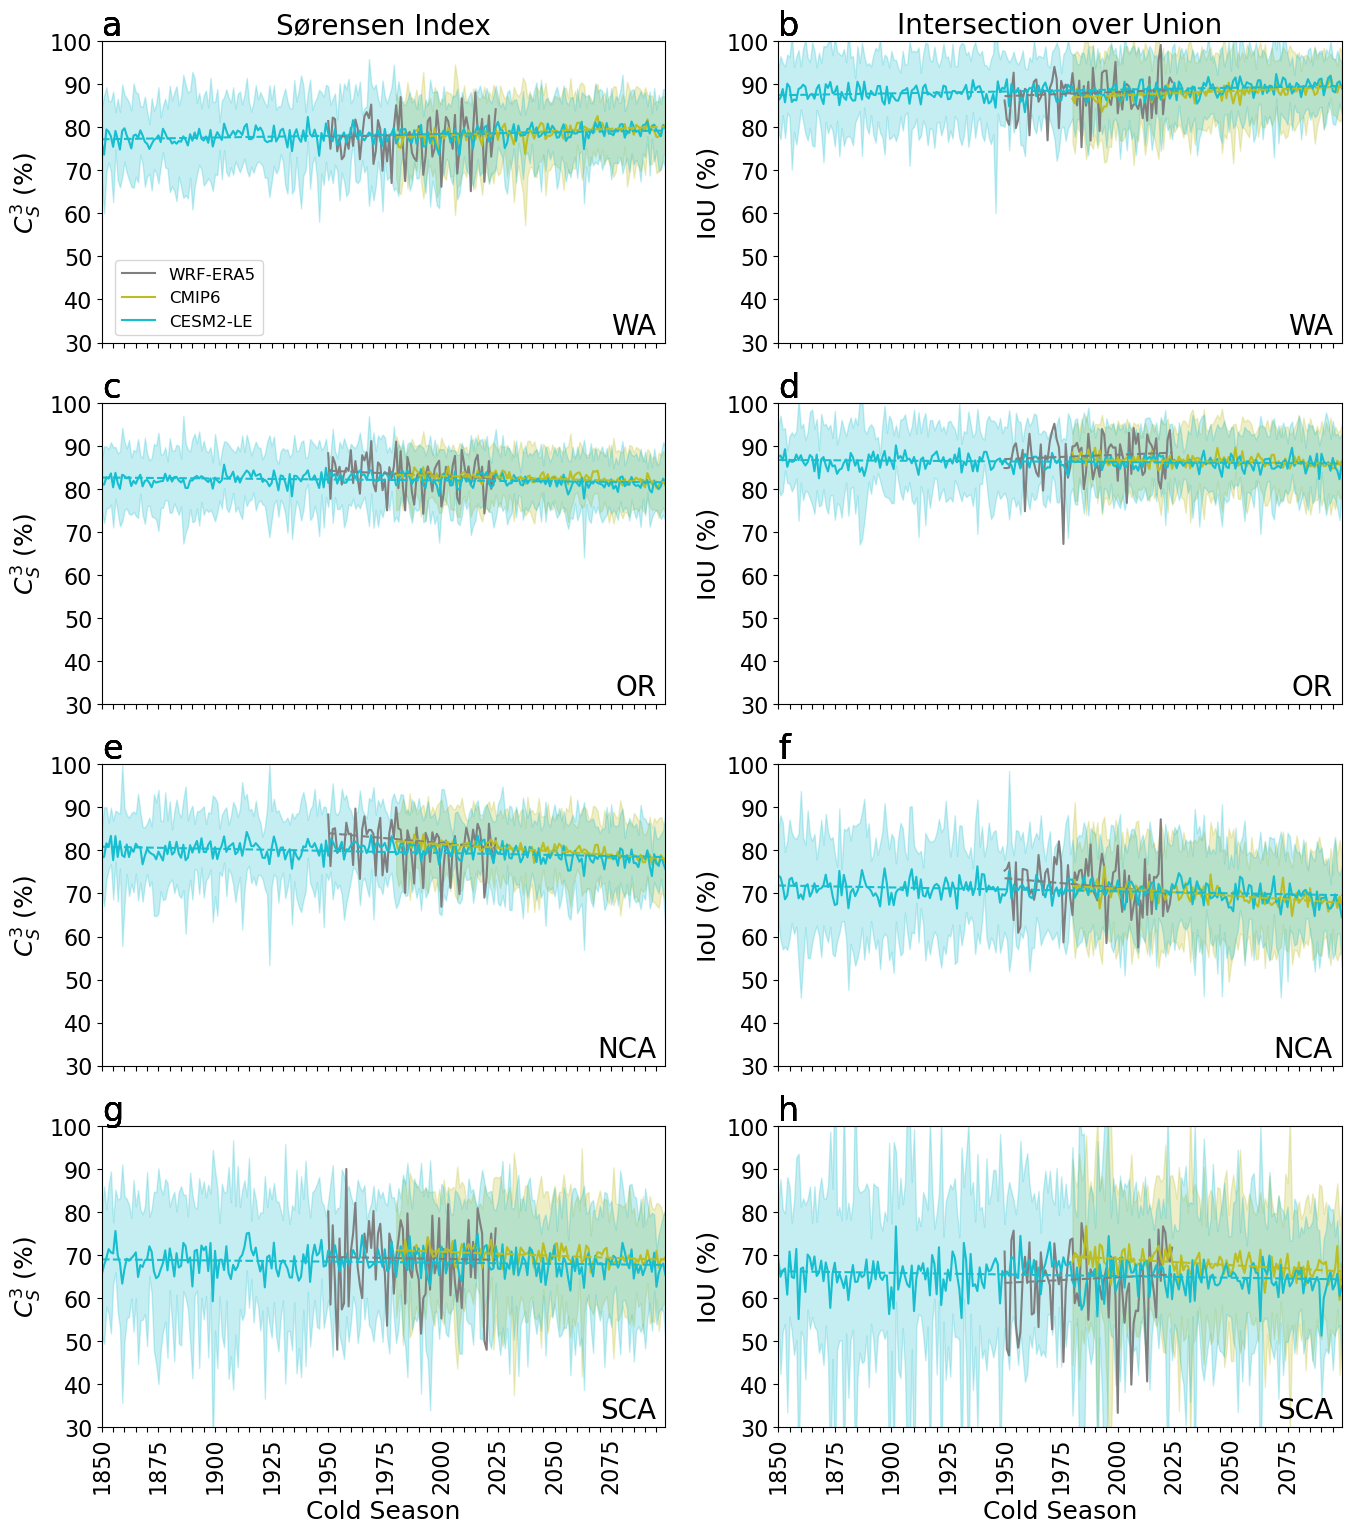

In [18]:
# Plots the Sorensen Index and IoU in adjacent colums for all four lat. zones (rows).

f11, a11 = plt.subplots(4,2, figsize=(16, 18))
sorsym = r'$C_S^3$'
sorsym_bar = r'$\bar{C_S^3}$'

for i in range(8):
    a11[i%4, i//4].set_xlim(1850, 2099)
    a11[i%4, i//4].set_ylim(30, 100)
    yticks = np.arange(30, 101, 10)
    a11[i%4, i//4].set_yticks(yticks)
    ylabels = [str(t) if t % 10 == 0 else '' for t in yticks]
    a11[i%4, i//4].set_yticklabels(ylabels, fontsize=16)


for i in range(2):
    xticks = np.arange(1850, 2100, 5)
    xlabels = [str(t) if t % 25 == 0 else '' for t in xticks]
    for j in range(3):
        a11[j, i].set_xticks(np.arange(1850, 2100, 5))
        a11[j, i].set_xticklabels(['']*len(xticks))
    a11[3, i].set_xticks(xticks)
    a11[3, i].set_xticklabels(xlabels,rotation=90, fontsize=16)

a11[0, 0].set_title(f"Sørensen Index", fontsize=20)
a11[0, 1].set_title(f"Intersection over Union", fontsize=20)

for ct, region in enumerate(['SCA', 'NCA', 'OR', 'WA']):
    sindx_era5_mean = np.load(f'intermediate_numpy_files/sindx_era5_{region}.npy')
    iou_era5_mean = iou_era5.sel(region=region).mean_iou*100

    sindx_cmip6 = np.load(f'intermediate_numpy_files/sindx_cmip6_{region}.npy')
    sindx_cmip6_mean = np.mean(sindx_cmip6, axis=0)
    sindx_cmip6_std = np.std(sindx_cmip6, axis=0)
    iou_cmip6_mean = iou_cmip6.sel(region=region).mean(dim='config').mean_iou*100
    iou_cmip6_std = iou_cmip6.sel(region=region).std(dim='config').mean_iou*100

    sindx_cesm2le = np.load(f'intermediate_numpy_files/sindx_cesm2le_{region}.npy')
    sindx_cesm2le_mean = np.mean(sindx_cesm2le, axis=0)
    sindx_cesm2le_std = np.std(sindx_cesm2le, axis=0)
    iou_cesm2le_mean = iou_cesm2le.sel(region=region).mean(dim='config').mean_iou*100
    iou_cesm2le_std = iou_cesm2le.sel(region=region).std(dim='config').mean_iou*100

    a11[3-ct, 0].text(2095, 32, region, fontsize=20, ha='right')
    a11[3-ct, 1].text(2095, 32, region, fontsize=20, ha='right')
    
    a11[3-ct, 0].plot(np.arange(1950, 2025), sindx_era5_mean, label='WRF-ERA5', color='C7')
    a11[3-ct, 0].plot(np.arange(1980, 2100), sindx_cmip6_mean, label='CMIP6', color='C8')
    a11[3-ct, 0].plot(np.arange(1850, 2100), sindx_cesm2le_mean, label='CESM2-LE', color='C9')
    a11[3-ct, 1].plot(np.arange(1950, 2025), iou_era5_mean, label='WRF-ERA5', color='C7')
    a11[3-ct, 1].plot(np.arange(1980, 2100), iou_cmip6_mean, label='CMIP6', color='C8')
    a11[3-ct, 1].plot(np.arange(1850, 2100), iou_cesm2le_mean, label='CESM2-LE', color='C9')

    # Calculate trend lines for each ensemble, and if the trend is statsitically significant.
    mktrend_sindx_era5 = mk.original_test(sindx_era5_mean)
    mktrend_sindx_cmip6 = mk.original_test(sindx_cmip6_mean)
    mktrend_sindx_cesm2le = mk.original_test(sindx_cesm2le_mean)
    mktrend_iou_era5 = mk.original_test(iou_era5_mean)
    mktrend_iou_cmip6 = mk.original_test(iou_cmip6_mean)
    mktrend_iou_cesm2le = mk.original_test(iou_cesm2le_mean)
    
    sindx_era5_label = f"{sorsym_bar}={mktrend_sindx_era5.slope:.3f}x + {mktrend_sindx_era5.intercept:.2f}*" if mktrend_sindx_era5.p < 0.05 else f"{sorsym_bar}={mktrend_sindx_era5.slope:.3f}x + {mktrend_sindx_era5.intercept:.2f}"
    sindx_cmip6_label = f"{sorsym_bar}={mktrend_sindx_cmip6.slope:.3f}x + {mktrend_sindx_cmip6.intercept:.2f}*" if mktrend_sindx_cmip6.p < 0.05 else f"{sorsym_bar}={mktrend_sindx_cmip6.slope:.3f}x + {mktrend_sindx_cmip6.intercept:.2f}"
    sindx_cesm2le_label = f"{sorsym_bar}={mktrend_sindx_cesm2le.slope:.3f}x + {mktrend_sindx_cesm2le.intercept:.2f}*" if mktrend_sindx_cesm2le.p < 0.05 else f"{sorsym_bar}={mktrend_sindx_cesm2le.slope:.3f}x + {mktrend_sindx_cesm2le.intercept:.2f}"
    iou_era5_label = f"IOU={mktrend_iou_era5.slope:.3f}x + {mktrend_iou_era5.intercept:.2f}*" if mktrend_iou_era5.p < 0.05 else f"IOU={mktrend_iou_era5.slope:.3f}x + {mktrend_iou_era5.intercept:.2f}"
    iou_cmip6_label = f"IOU={mktrend_iou_cmip6.slope:.3f}x + {mktrend_iou_cmip6.intercept:.2f}*" if mktrend_iou_cmip6.p < 0.05 else f"IOU={mktrend_iou_cmip6.slope:.3f}x + {mktrend_iou_cmip6.intercept:.2f}"
    iou_cesm2le_label = f"IOU={mktrend_iou_cesm2le.slope:.3f}x + {mktrend_iou_cesm2le.intercept:.2f}*" if mktrend_iou_cesm2le.p < 0.05 else f"IOU={mktrend_iou_cesm2le.slope:.3f}x + {mktrend_iou_cesm2le.intercept:.2f}"
    
    
    a11[3-ct, 0].plot(np.arange(1950,2025), mktrend_sindx_era5.slope * np.arange(75) + mktrend_sindx_era5.intercept, color='C7', linestyle='dashed')
    a11[3-ct, 0].plot(np.arange(1980,2100), mktrend_sindx_cmip6.slope * np.arange(120) + mktrend_sindx_cmip6.intercept, color='C8', linestyle='dashed')
    a11[3-ct, 0].plot(np.arange(1850,2100), mktrend_sindx_cesm2le.slope * np.arange(250) + mktrend_sindx_cesm2le.intercept, color='C9', linestyle='dashed')
    a11[3-ct, 1].plot(np.arange(1950,2025), mktrend_iou_era5.slope * np.arange(75) + mktrend_iou_era5.intercept, color='C7', linestyle='dashed')
    a11[3-ct, 1].plot(np.arange(1980,2100), mktrend_iou_cmip6.slope * np.arange(120) + mktrend_iou_cmip6.intercept, color='C8', linestyle='dashed')
    a11[3-ct, 1].plot(np.arange(1850,2100), mktrend_iou_cesm2le.slope * np.arange(250) + mktrend_iou_cesm2le.intercept, color='C9', linestyle='dashed')

    a11[3-ct, 0].fill_between(np.arange(1980, 2100), sindx_cmip6_mean - 1.96 * sindx_cmip6_std, sindx_cmip6_mean + 1.96 * sindx_cmip6_std, color='C8', alpha=0.25)
    a11[3-ct, 0].fill_between(np.arange(1850, 2100), sindx_cesm2le_mean - 1.96 * sindx_cesm2le_std, sindx_cesm2le_mean + 1.96 * sindx_cesm2le_std, color='C9', alpha=0.25)
    a11[3-ct, 1].fill_between(np.arange(1980, 2100), iou_cmip6_mean - 1.96 * iou_cmip6_std, iou_cmip6_mean + 1.96 * iou_cmip6_std, color='C8', alpha=0.25)
    a11[3-ct, 1].fill_between(np.arange(1850, 2100), iou_cesm2le_mean - 1.96 * iou_cesm2le_std, iou_cesm2le_mean + 1.96 * iou_cesm2le_std, color='C9', alpha=0.25)

    if ct == 3:
        a11[3, 0].set_xlabel("Cold Season", fontsize=18)
        a11[3, 1].set_xlabel("Cold Season", fontsize=18)
    a11[3-ct, 0].set_ylabel(f"{sorsym} (%)", fontsize=18)
    a11[3-ct, 1].set_ylabel(f"IoU (%)", fontsize=18)

    h0, l0 = a11[3-ct, 0].get_legend_handles_labels()
    h1, l1 = a11[3-ct, 1].get_legend_handles_labels()
    h2, l2 = a11[3-ct, 1].get_legend_handles_labels()

    if ct==3:
        a11[3-ct, 0].legend(handles=h2[:3], labels=l2[:3], bbox_to_anchor=(0.3, 0.3), fontsize=12)
    # In-line print of the trendlines for each ensemble. Table 2 also uses this.
    print(region)
    print(f"{sindx_era5_label}\n{sindx_cmip6_label}\n{sindx_cesm2le_label}\n{iou_era5_label}\n{iou_cmip6_label}\n{iou_cesm2le_label}")

    for i in range(8):
        a11[i//2, i%2].text(0, 1.02, string.ascii_lowercase[i], fontsize=24, transform=a11[i//2, i%2].transAxes)

In [18]:
f11.savefig('/glade/work/tcorrie/ARdata/Figures/sorensenindex_plus_iou_byregion.png', dpi=1200, bbox_inches='tight')

In [19]:
f11.savefig('/glade/work/tcorrie/ARdata/Figures/JoC/sorensenindex_plus_iou_byregion.png', dpi=1200, bbox_inches='tight') # Fig. 3